<a href="https://colab.research.google.com/github/otoperalias/Coyuntura/blob/main/clases/Tema3_V_32-11-2026.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## Tema 3.5. Modelos SARIMA y SARIMAX.

In [83]:
# Importamos funciones y establecemos configuración general
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.stattools import adfuller
plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams["figure.figsize"] = [10,4]  # Default figure size

In [84]:
# Generamos funciones que vamos a usar en el notebook
def DFtest(datos):
    print('Results of Dickey-Fuller Test (H0= NO estac.):')
    dftest = adfuller(datos, autolag='AIC')
    print('Test Statistic', dftest[0])
    print('p-value', dftest[1])
    print('#Lags Used', dftest[2])
    print('# obs', dftest[3])
    for k, v in dftest[4].items():
        print(k,v)

def forecast_accuracy(forecast, actual):
    rmse = np.sqrt(np.mean((forecast-actual)**2))
    mape = np.mean(np.abs(forecast - actual)/np.abs(actual))  # MAPE
    corr = np.corrcoef(forecast, actual)[0,1]   # corr
    print({'rmse':rmse,'mape':mape,'corr':corr})

### Modelo SARIMA

In [ ]:
# Importamos base de datos (sobre ventas de medicamentos)
# https://github.com/otoperalias/Coyuntura/blob/main/clases/datos/medicamentos_ventas.csv
# clicar en 'raw' y luego clicar en botón derecho y 'guardar como' .csv
#medic = pd.read_csv("medicamentos_ventas.csv",index_col=0,parse_dates=True)

# O directamente:
medic = pd.read_csv("https://raw.githubusercontent.com/otoperalias/Coyuntura/main/clases/datos/medicamentos_ventas.csv",index_col=0,parse_dates=True)

#Creamos test and training dataset
train=medic[:-24]
test=medic[-24:]

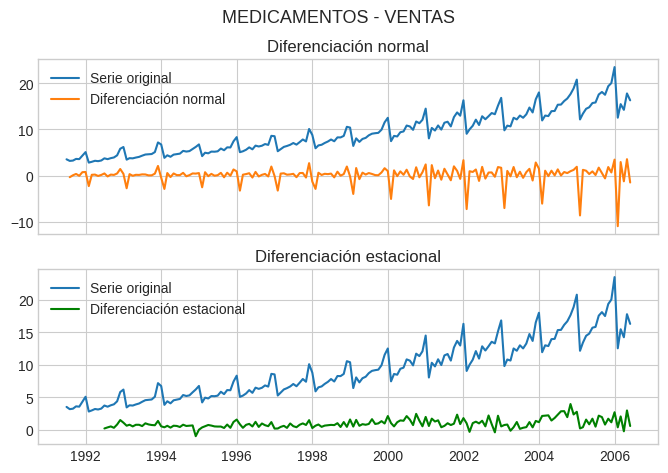

In [ ]:
# GRÁFICO
fig, axes = plt.subplots(2, 1, figsize=(8,5), dpi=100, sharex=True)
# Diferenciación normal
axes[0].plot(train, label='Serie original')
axes[0].plot(train.diff(1), label='Diferenciación normal')
axes[0].set_title('Diferenciación normal')
axes[0].legend(loc='upper left', fontsize=10)
# Diferenciación estacional
axes[1].plot(train, label='Serie original')
axes[1].plot(train.diff(12), label='Diferenciación estacional', color='green')
axes[1].set_title('Diferenciación estacional')
plt.legend(loc='upper left', fontsize=10)
plt.suptitle('MEDICAMENTOS - VENTAS', fontsize=13)
plt.show()

Se puede observar que los picos estacionales no resultan afectados cuando se realiza la diferenciación normal, mientras que al diferenciar de manera estacional, desaparecen.

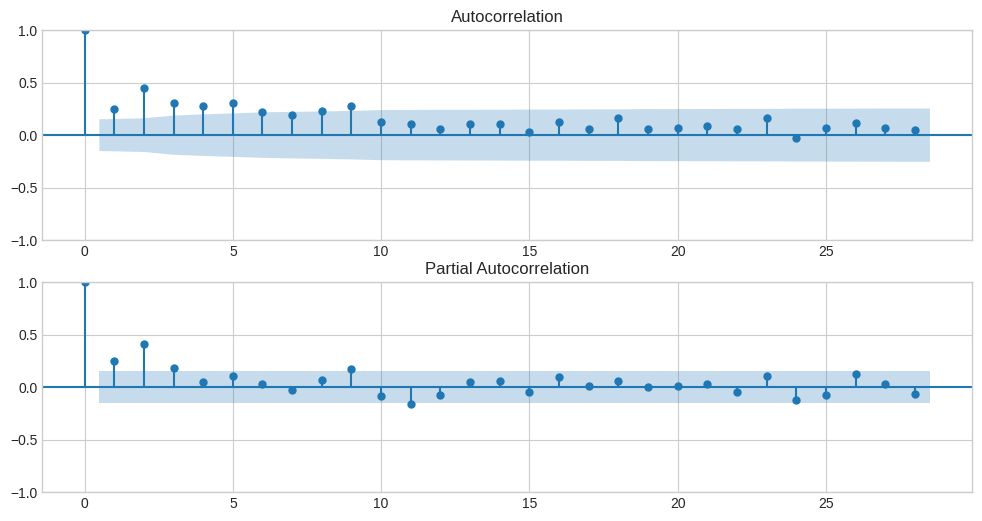

Results of Dickey-Fuller Test (H0= NO estac.):
Test Statistic -3.904014079051377
p-value 0.0020055034954935547
#Lags Used 2
# obs 165
1% -3.470616369591229
5% -2.8792214018977655
10% -2.57619681359045


/tmp/ipykernel_546/3763762766.py:4: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  dftest = adfuller(datos, autolag='AIC')


In [ ]:
# Dibujamos correlogramas y usamos el test DF
fig, ax = plt.subplots(2, figsize=(12,6))
ax[0] = plot_acf(train.diff(12).dropna(), ax=ax[0], lags=28)
ax[1] = plot_pacf(train.diff(12).dropna(), ax=ax[1], lags=28)
plt.show()
DFtest(train.diff(12).dropna())

Se rechaza la hipótesis nula y, por tanto, la serie con diferencias estacionales es estacionario.  
En caso de que la serie con diferencias estacionales fuera NO estacionaria, habría que tomar, a su vez, primeras diferencias: ```train.diff(12).diff()```.


Según el los gráficos de autocorrelación y correlación parcial, vemos que el modelo podría ser: SARIMA(2,0,2)(0,1,0,12)

#### Procedemos a construir el modelo:
Para más información sobre modelos SARIMAX:
*https://www.statsmodels.org/stable/generated/statsmodels.tsa.statespace.sarimax.SARIMAX.html
*https://www.statsmodels.org/stable/examples/notebooks/generated/statespace_sarimax_stata.html


In [ ]:
# Especificación del modelo
mod = sm.tsa.statespace.SARIMAX(train,order=(2,0,1),seasonal_order=(0,1,0,12), trend="c",
                                enforce_stationarity=False, enforce_invertibility=False)

/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)
/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)


In [ ]:
# Estimación del modelo y output de los resultados:v
results= mod.fit()
print(results.summary())   # vemos que la constante no es significativa y se podría quitar

                                      SARIMAX Results                                      
Dep. Variable:                               value   No. Observations:                  180
Model:             SARIMAX(2, 0, 1)x(0, 1, [], 12)   Log Likelihood                -155.886
Date:                             Mon, 23 Nov 2026   AIC                            321.772
Time:                                     10:36:51   BIC                            337.332
Sample:                                 07-01-1991   HQIC                           328.088
                                      - 06-01-2006                                         
Covariance Type:                               opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
intercept      0.1696      0.077      2.200      0.028       0.019       0.321
ar.L1          0.5107      

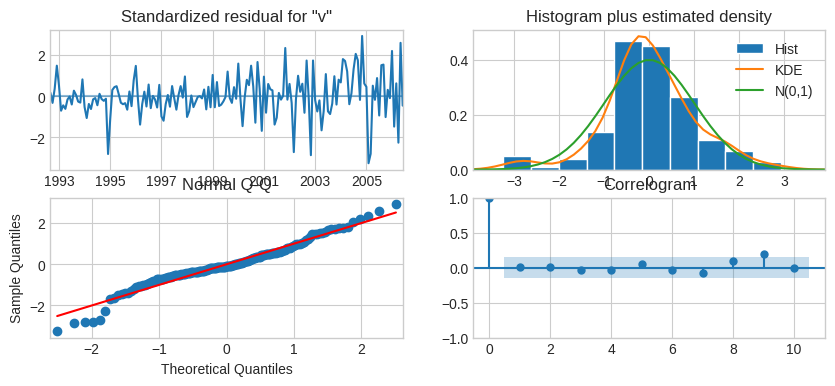

In [ ]:
# Podemos dibujar los errores
results.plot_diagnostics()
plt.show()

#### ¿Cómo de preciso es nuestro modelo para predecir?

In [ ]:
# Realizo la predicción para el periodo de la "test dataset" y calculo su exactitud (acccuracy)
pred = results.get_prediction('2006-07-01','2008-06-01', dynamic=False)
forecast_accuracy(pred.predicted_mean, test.value)

{'rmse': np.float64(3.331087569875257), 'mape': np.float64(0.1312102711299147), 'corr': np.float64(0.806339706578606)}


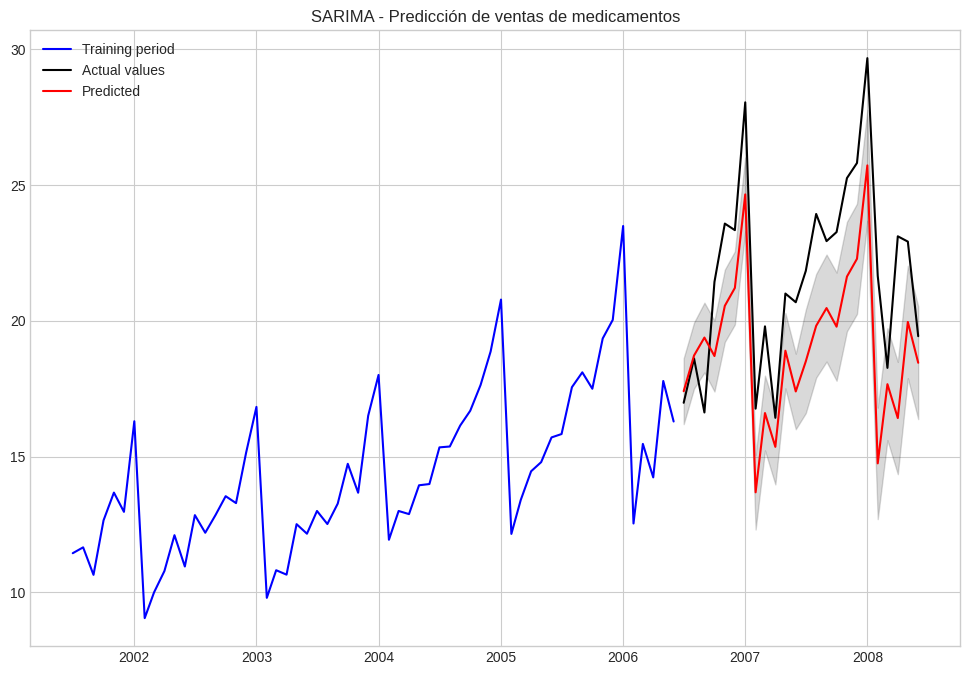

In [ ]:
# Dibujamos la predicción:
pred_ci = pred.conf_int()
# Creando las series para su representación gráfica
fitted_series = pred.predicted_mean
lower_series = pred_ci["lower value"]
upper_series = pred_ci["upper value"]
# Gráfico -
fig,ax=plt.subplots(figsize=(12,8))
ax.plot(train[-60:], label="Training period", color="b") #con [-60:] evito representar la serie completa
ax.plot(test, label="Actual values", color="k")
ax.plot(fitted_series, label="Predicted", color='r')
ax.fill_between(lower_series.index,
                 lower_series,
                 upper_series,
                 color='k', alpha=.15)
ax.legend()
ax.set_title("SARIMA - Predicción de ventas de medicamentos")
plt.show()

/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)
/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)


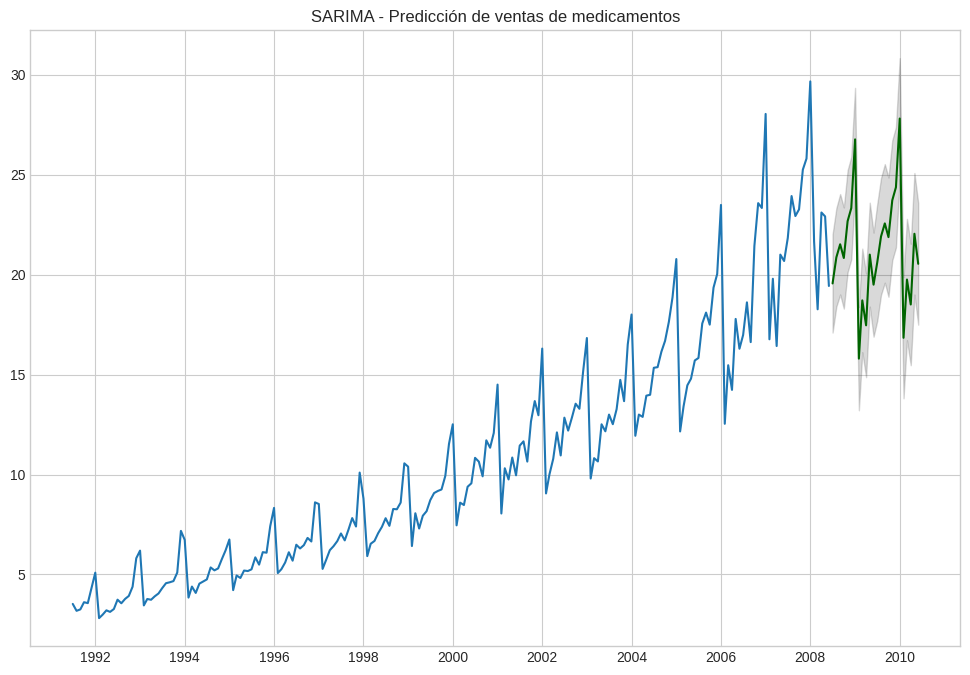

In [ ]:
# Y también predecimos hacia el futuro
mod = sm.tsa.statespace.SARIMAX(medic,order=(2,0,1),seasonal_order=(0,1,0,12), trend="c",
                                enforce_stationarity=False, enforce_invertibility=False)
pred = results.get_prediction(start="2008-07-01",end="2010-06-01")
pred_ci = pred.conf_int()
# Creando las series para su representación gráfica
fitted_series = pred.predicted_mean
lower_series = pred_ci["lower value"]
upper_series = pred_ci["upper value"]
# Gráfico
fig,ax=plt.subplots(figsize=(12,8))
ax.plot(medic)
ax.plot(fitted_series, color='darkgreen')
ax.fill_between(lower_series.index,
                 lower_series,
                 upper_series,
                 color='k', alpha=.15)
ax.set_title("SARIMA - Predicción de ventas de medicamentos")
plt.show()

### Modelo SARIMAX

La predicción del modelo SARIMA es mejorable (*rmse*=3.31, *mape*= 0.13, *corr*= 0.81) y nos gustaría que fuera más buena.  
Si tuviéramos un indicador correlacionado con las ventas de medicamentos y que estuviera disponible antes, sería muy útil para ayudarnos a predecir. Ese indicador sería la variable e**X**ógena del modelo *SARIMAX*.

In [ ]:
# Datos de la variable exógena: número de visitas a atención primaria
# https://github.com/otoperalias/Coyuntura/blob/main/clases/datos/medic_visitas_doctor.xlsx

# visit = pd.read_excel("medic_visitas_doctor.xlsx", index_col=0, parse_dates=True)

# O directamente leemos del url:
visit = pd.read_excel("https://github.com/otoperalias/Coyuntura/raw/refs/heads/main/clases/datos/medic_visitas_doctor.xlsx", index_col=0, parse_dates=True)

visit

,visitas
date,
1991-07-01,40000
1991-08-01,38257
1991-09-01,38762
1991-10-01,41165
1991-11-01,41056
...,...
2008-08-01,141151
2008-09-01,147381
2008-10-01,149323


In [ ]:
# Dividir la serie en c subseries

x_train=visit.loc["1991-07-01":"2006-06-01"]
x_test=visit.loc["2006-07-01":"2008-06-01"]
x_out=visit.loc["2008-07-01":"2008-12-01"]
print(len(x_train))
print(len(x_test))
print(len(x_out))

180
24
6


Esta serie tienes 6 observaciones más, las cuales vamos utilizar para mejorar la predicción.

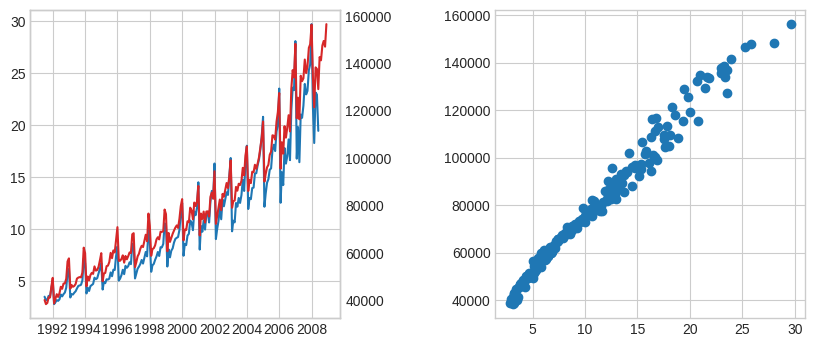

0.989792168753025


In [ ]:
# Visualizamos
fig,ax=plt.subplots(1,2,figsize=(10,4))
ax[0].plot(medic)
ax01 = ax[0].twinx()  # aquí se establece un segundo eje Y que comparte el mismo eje X
ax01.plot(visit,color='tab:red')
ax01.grid(False)
ax[1].scatter(medic.value,visit.visitas[:204]) # vemos que hay una correlación alta y por tanto puede usarse como variable exógena
plt.subplots_adjust(wspace=0.5)
plt.show()

#Calculamos correlación para la train
print(np.corrcoef(train.value,x_train.visitas)[0,1])

Vemos que las dos series están muy correlacionadas y por tanto la variable visitas puede usarse como eXógena.

#### Construimos el modelo:

In [ ]:
# Especificamos y estimamos el modelo
results = sm.tsa.statespace.SARIMAX(train,exog=x_train, order=(2,0,1),seasonal_order=(0,1,0,12), trend="c",
                                    enforce_stationarity=False, enforce_invertibility=False).fit()
print(results.summary())

/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)
/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)


                                      SARIMAX Results                                      
Dep. Variable:                               value   No. Observations:                  180
Model:             SARIMAX(2, 0, 1)x(0, 1, [], 12)   Log Likelihood                 -51.309
Date:                             Mon, 23 Nov 2026   AIC                            114.618
Time:                                     11:03:01   BIC                            133.290
Sample:                                 07-01-1991   HQIC                           122.197
                                      - 06-01-2006                                         
Covariance Type:                               opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
intercept      0.0018      0.030      0.059      0.953      -0.057       0.061
visitas        0.0002   9.2

#### Capacidad para predecir:

In [ ]:
# Capacidad para predecir
pred = results.get_prediction('2006-07-01','2008-06-01', exog=x_test, dynamic=False)
forecast_accuracy(pred.predicted_mean, test.value)

{'rmse': np.float64(0.6398368133501752), 'mape': np.float64(0.023652256861257905), 'corr': np.float64(0.9844317214831275)}


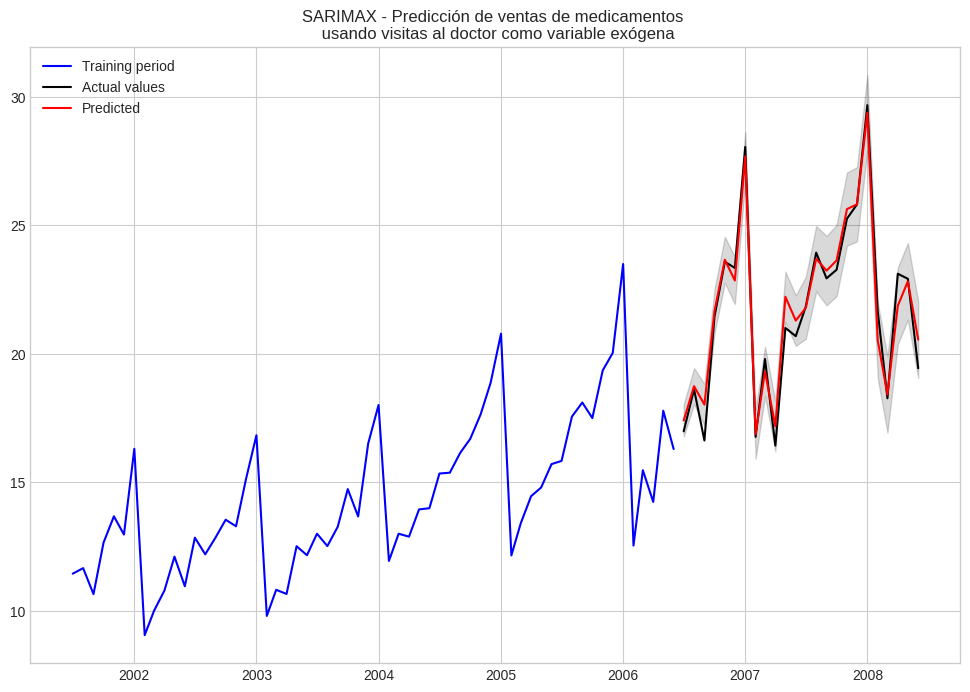

In [ ]:
# Dibujamos la predicción:
pred_ci = pred.conf_int()
# Creando las series para su representación gráfica
fitted_series = pred.predicted_mean
lower_series = pred_ci["lower value"]
upper_series = pred_ci["upper value"]
# Gráfico -
fig,ax=plt.subplots(figsize=(12,8))
ax.plot(train[-60:], label="Training period", color="b") #con [-60:] evito representar la serie completa
ax.plot(test, label="Actual values", color="k")
ax.plot(fitted_series, label="Predicted", color='r')
ax.fill_between(lower_series.index,
                 lower_series,
                 upper_series,
                 color='k', alpha=.15)
ax.legend()
ax.set_title("SARIMAX - Predicción de ventas de medicamentos \n usando visitas al doctor como variable exógena")
plt.show()

Y también predecimos hacia el futuro. Dado que visit llega a 2008-12-01 (mientras medic hasta 2008-06-01), predecimos seis meses.

/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)
/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)


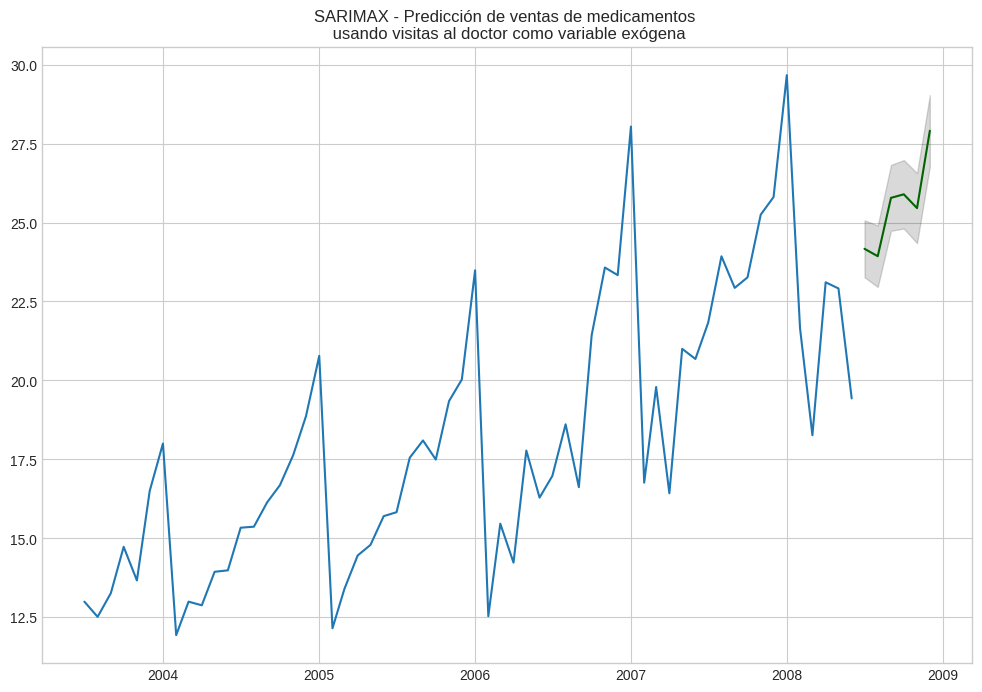

In [ ]:
# Predecimos hacia el futuro:
exog_in=visit[:-6]
results = sm.tsa.statespace.SARIMAX(medic,exog=exog_in, order=(2,0,1),seasonal_order=(0,1,0,12), trend="c",
                                    enforce_stationarity=False, enforce_invertibility=False).fit()
pred = results.get_prediction(start="2008-07-01",end="2008-12-01", exog=x_out)
pred_ci = pred.conf_int()
# Creando las series para su representación gráfica
fitted_series = pred.predicted_mean
lower_series = pred_ci["lower value"]
upper_series = pred_ci["upper value"]
# Gráfico
fig,ax=plt.subplots(figsize=(12,8))
ax.plot(medic[-60:])
ax.plot(fitted_series, color='darkgreen')
ax.fill_between(lower_series.index,
                 lower_series,
                 upper_series,
                 color='k', alpha=.15)
ax.set_title("SARIMAX - Predicción de ventas de medicamentos \n usando visitas al doctor como variable exógena")
plt.show()

## Ejercicio: modelización del crecimiento del PIB interanual de España con el modelo SARIMA  y SARIMAX.  

Datos a utilizar:
https://github.com/otoperalias/Coyuntura/blob/main/clases/datos/Clase_SarimaxDatos.xlsx

In [85]:
#Importamos y procesamos
pib=pd.read_excel("/content/Clase_SarimaxDatos.xlsx",sheet_name="PIB INE-CNTR")
pib=pib.iloc[3:129]
pib.columns=["periodo","ive"]
pib['periodo']=pib.periodo.str[:4]+"Q"+pib.periodo.str[-1:]
pib['periodo']=pd.to_datetime(pib['periodo'])
pib.set_index("periodo",inplace=True)
pib=pib.astype(float)

# Train/test split
train=pib.loc["1995-01-01":"2024-04-01"]
test=pib.loc["2024-07-01":"2026-07-01"]
print(len(train),len(test))


118 8


/tmp/ipykernel_794/4049320057.py:6: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  pib['periodo']=pd.to_datetime(pib['periodo'])


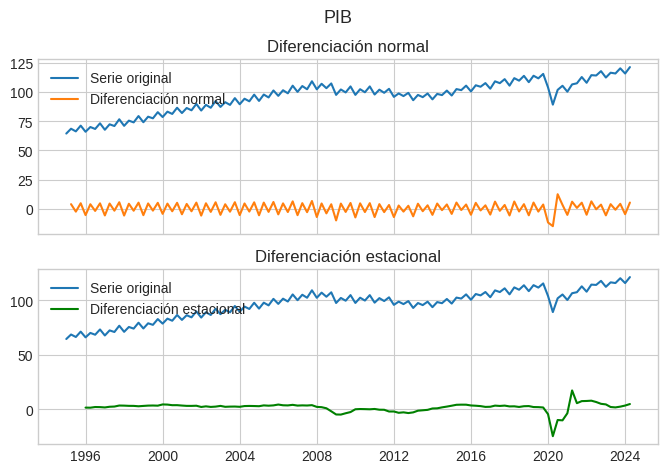

In [86]:
# GRÁFICO
fig, axes = plt.subplots(2, 1, figsize=(8,5), dpi=100, sharex=True)
# Diferenciación normal
axes[0].plot(train, label='Serie original')
axes[0].plot(train.diff(1), label='Diferenciación normal')
axes[0].set_title('Diferenciación normal')
axes[0].legend(loc='upper left', fontsize=10)
# Diferenciación estacional
axes[1].plot(train, label='Serie original')
axes[1].plot(train.diff(4), label='Diferenciación estacional', color='green')
axes[1].set_title('Diferenciación estacional')
plt.legend(loc='upper left', fontsize=10)
plt.suptitle('PIB', fontsize=13)
plt.show()

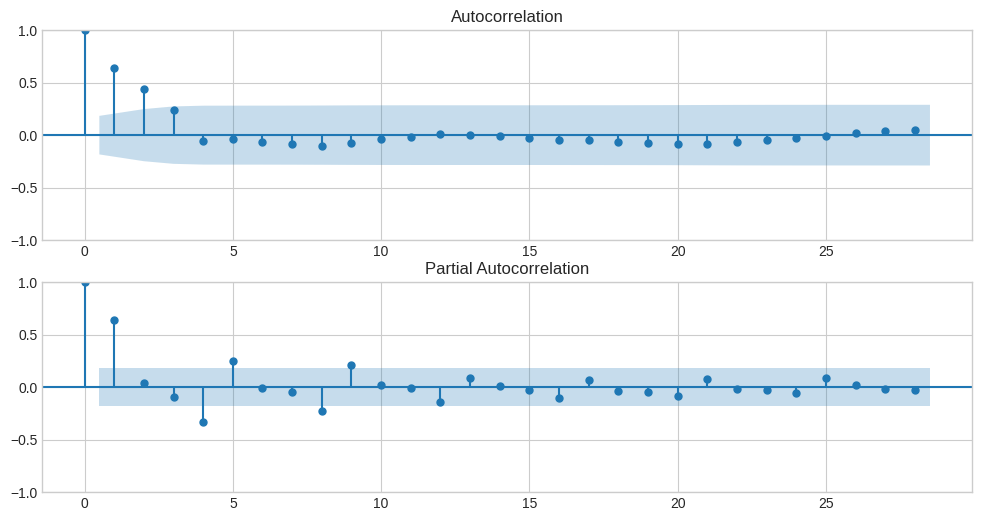

Results of Dickey-Fuller Test (H0= NO estac.):
Test Statistic -2.8422449251642696
p-value 0.05248815120152313
#Lags Used 8
# obs 105
1% -3.4942202045135513
5% -2.889485291005291
10% -2.5816762131519275


/tmp/ipykernel_794/3763762766.py:4: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  dftest = adfuller(datos, autolag='AIC')


In [87]:
# Dibujamos correlogramas y usamos el test DF
fig, ax = plt.subplots(2, figsize=(12,6))
ax[0] = plot_acf(train.diff(4).dropna(), ax=ax[0], lags=28)
ax[1] = plot_pacf(train.diff(4).dropna(), ax=ax[1], lags=28)
plt.show()
DFtest(train.diff(4).dropna())

In [88]:
mod = sm.tsa.statespace.SARIMAX(train,order=(1,0,0),seasonal_order=(1,1,0,4), trend="c",
                                enforce_stationarity=False, enforce_invertibility=False)
# Estimación del modelo y output de los resultados:v
results= mod.fit()
#print(results.summary())   # vemos que la constante no es significativa y se podría quitar

/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency QS-OCT will be used.
  self._init_dates(dates, freq)
/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency QS-OCT will be used.
  self._init_dates(dates, freq)


In [89]:
# Realizo la predicción para el periodo de la "test dataset" y calculo su exactitud (acccuracy)
pred = results.get_prediction('2024-07-01','2026-04-01', dynamic=False)
forecast_accuracy(pred.predicted_mean, test.ive)

{'rmse': np.float64(1.7241263556806545), 'mape': np.float64(0.011868778307897678), 'corr': np.float64(0.9875490159525354)}


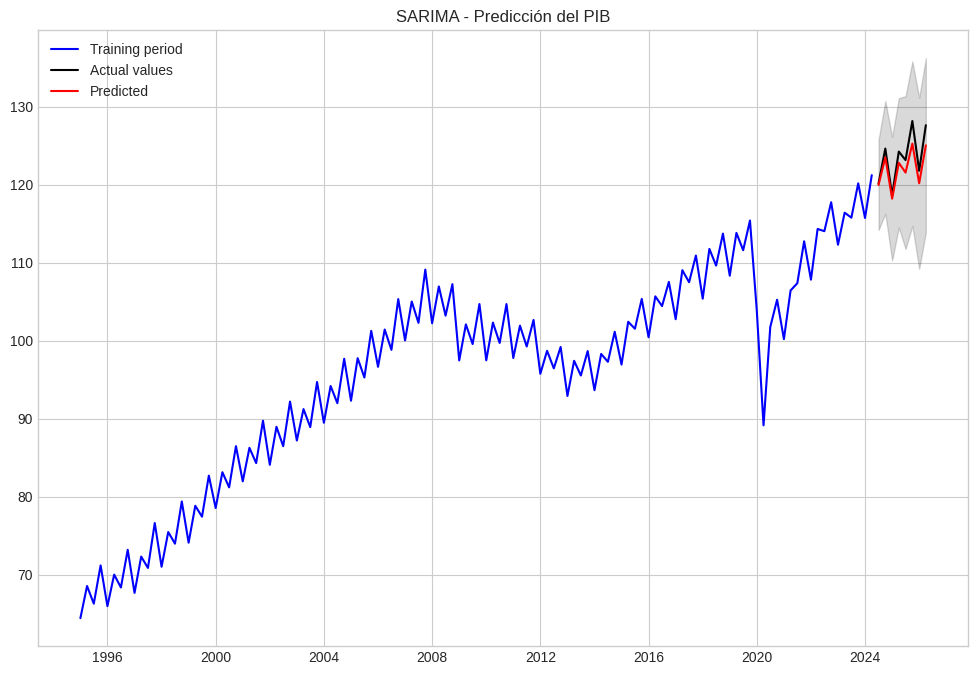

In [90]:
# Dibujamos la predicción:
pred_ci = pred.conf_int()
# Creando las series para su representación gráfica
fitted_series = pred.predicted_mean
lower_series = pred_ci["lower ive"]
upper_series = pred_ci["upper ive"]
# Gráfico -
fig,ax=plt.subplots(figsize=(12,8))
ax.plot(train, label="Training period", color="b") #con [-60:] evito representar la serie completa
ax.plot(test, label="Actual values", color="k")
ax.plot(fitted_series, label="Predicted", color='r')
ax.fill_between(lower_series.index,
                 lower_series,
                 upper_series,
                 color='k', alpha=.15)
ax.legend()
ax.set_title("SARIMA - Predicción del PIB")
plt.show()

/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency QS-OCT will be used.
  self._init_dates(dates, freq)
/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency QS-OCT will be used.
  self._init_dates(dates, freq)


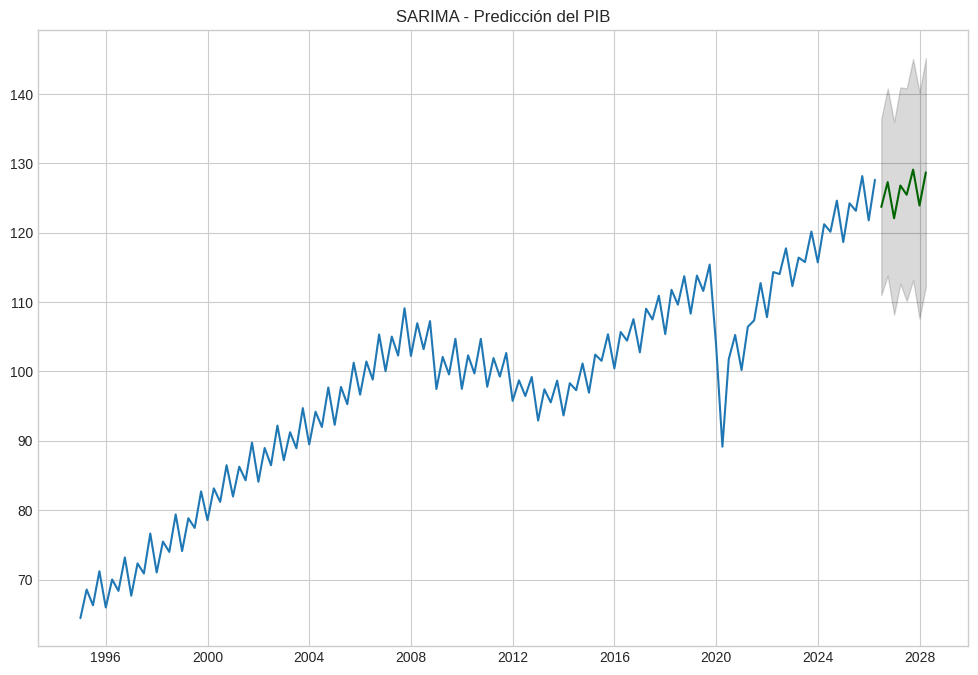

In [91]:
# Y también predecimos hacia el futuro
mod = sm.tsa.statespace.SARIMAX(pib,order=(1,0,0),seasonal_order=(1,1,0,4), trend="c",
                                enforce_stationarity=False, enforce_invertibility=False)
pred = results.get_prediction(start="2026-07-01",end="2028-04-01")
pred_ci = pred.conf_int()
# Creando las series para su representación gráfica
fitted_series = pred.predicted_mean
lower_series = pred_ci["lower ive"]
upper_series = pred_ci["upper ive"]
# Gráfico
fig,ax=plt.subplots(figsize=(12,8))
ax.plot(pib)
ax.plot(fitted_series, color='darkgreen')
ax.fill_between(lower_series.index,
                 lower_series,
                 upper_series,
                 color='k', alpha=.15)
ax.set_title("SARIMA - Predicción del PIB")
plt.show()

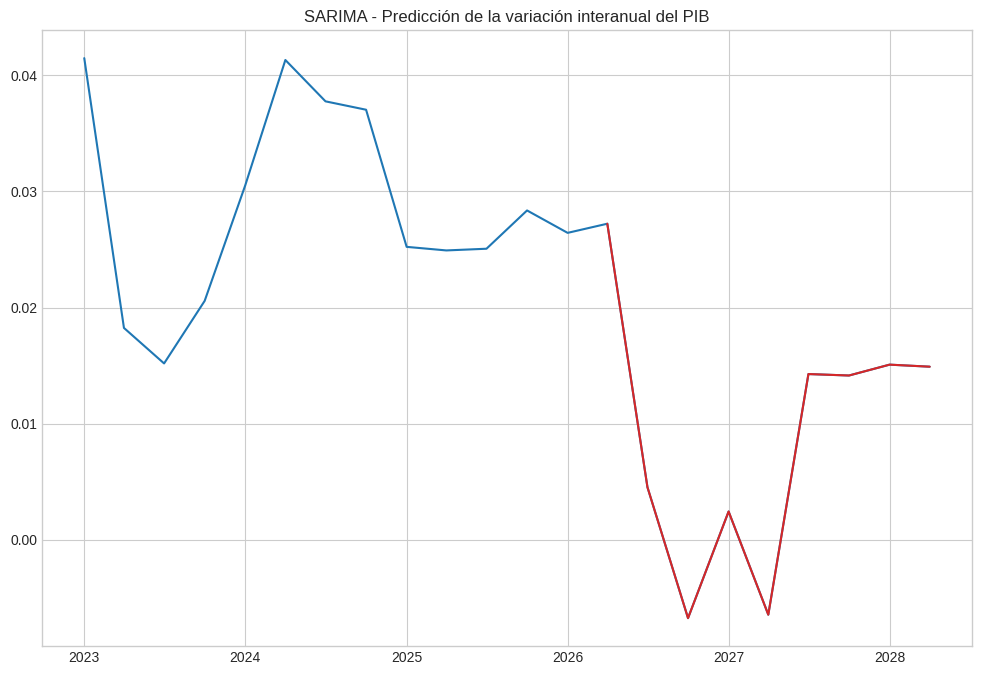

In [92]:
# Ahora, en tasas de crecimiento

fitted_series.rename("ive", inplace=True)
#Creación serie enlazada
serie_enlazada=pd.concat([pib,fitted_series])

fig,ax=plt.subplots(figsize=(12,8))
ax.plot(serie_enlazada["2022":].pct_change(4))
ax.plot(serie_enlazada["2025-04-01":].pct_change(4), color="tab:red")

ax.set_title("SARIMA - Predicción de la variación interanual del PIB")
plt.show()

In [95]:
# ESTIMACIÓN SARIMA CON TASA DE VARIACIÓN INTERANUAL

#Importamos y procesamos
tvpib=pib.pct_change(4)

# Train/test split
train=tvpib.loc["1996-01-01":"2024-04-01"]  # Ahora empezamos en el 96, pues para el 95 no se puede calcular
test=tvpib.loc["2024-07-01":"2026-07-01"]
print(len(train),len(test))

114 8


<Axes: xlabel='periodo'>

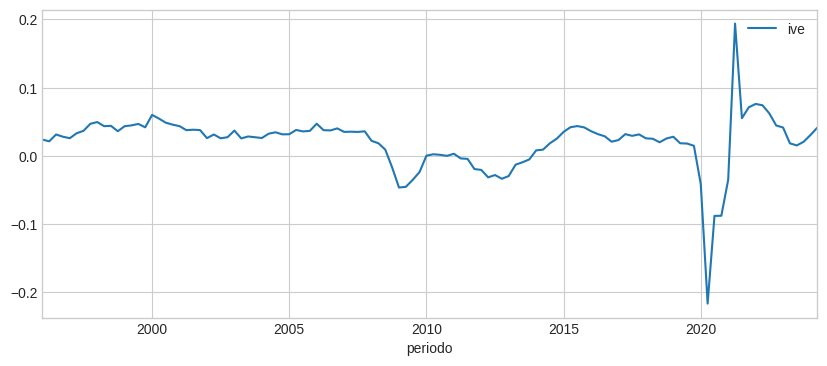

In [96]:
train.plot()

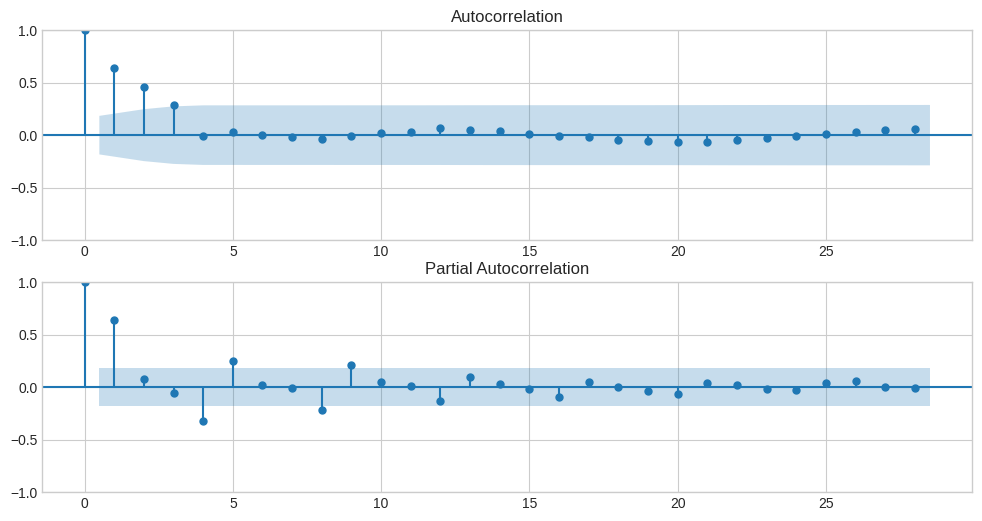

Results of Dickey-Fuller Test (H0= NO estac.):
Test Statistic -2.7063459430715024
p-value 0.07294656662202252
#Lags Used 8
# obs 105
1% -3.4942202045135513
5% -2.889485291005291
10% -2.5816762131519275


/tmp/ipykernel_794/3763762766.py:4: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  dftest = adfuller(datos, autolag='AIC')


In [98]:
# Dibujamos correlogramas y usamos el test DF
fig, ax = plt.subplots(2, figsize=(12,6))
ax[0] = plot_acf(train.dropna(), ax=ax[0], lags=28)
ax[1] = plot_pacf(train.dropna(), ax=ax[1], lags=28)
plt.show()
DFtest(train.dropna())

In [99]:
mod = sm.tsa.statespace.SARIMAX(train,order=(1,0,2),seasonal_order=(1,0,0,4), trend="c",
                                enforce_stationarity=False, enforce_invertibility=False)
# Estimación del modelo y output de los resultados:v
results= mod.fit()
print(results.summary())   # vemos que la constante no es significativa y se podría quitar

/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency QS-OCT will be used.
  self._init_dates(dates, freq)
/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency QS-OCT will be used.
  self._init_dates(dates, freq)


                                     SARIMAX Results                                      
Dep. Variable:                                ive   No. Observations:                  114
Model:             SARIMAX(1, 0, 2)x(1, 0, [], 4)   Log Likelihood                 231.578
Date:                            Tue, 24 Nov 2026   AIC                           -451.155
Time:                                    10:01:47   BIC                           -435.007
Sample:                                01-01-1996   HQIC                          -444.607
                                     - 04-01-2024                                         
Covariance Type:                              opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
intercept      0.0061      0.003      2.096      0.036       0.000       0.012
ar.L1          0.7901      0.174   

In [100]:
pred = results.get_prediction('2024-07-01','2026-04-01', dynamic=False)
forecast_accuracy(pred.predicted_mean, test.ive)

{'rmse': np.float64(0.004353179729963907), 'mape': np.float64(0.13968053461512572), 'corr': np.float64(0.9019145903580572)}


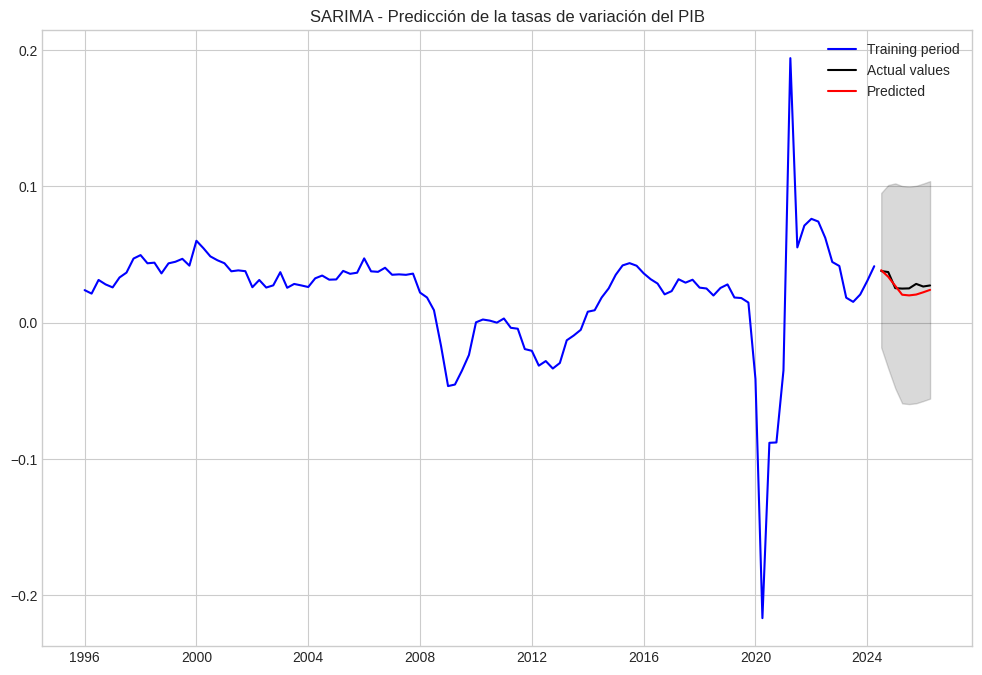

In [102]:
# Dibujamos la predicción:
pred_ci = pred.conf_int()
# Creando las series para su representación gráfica
fitted_series = pred.predicted_mean
lower_series = pred_ci["lower ive"]
upper_series = pred_ci["upper ive"]
# Gráfico -
fig,ax=plt.subplots(figsize=(12,8))
ax.plot(train, label="Training period", color="b") #con [-60:] evito representar la serie completa
ax.plot(test, label="Actual values", color="k")
ax.plot(fitted_series, label="Predicted", color='r')
ax.fill_between(lower_series.index,
                 lower_series,
                 upper_series,
                 color='k', alpha=.15)
ax.legend()
ax.set_title("SARIMA - Predicción de la tasas de variación del PIB")
plt.show()

/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency QS-OCT will be used.
  self._init_dates(dates, freq)
/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency QS-OCT will be used.
  self._init_dates(dates, freq)


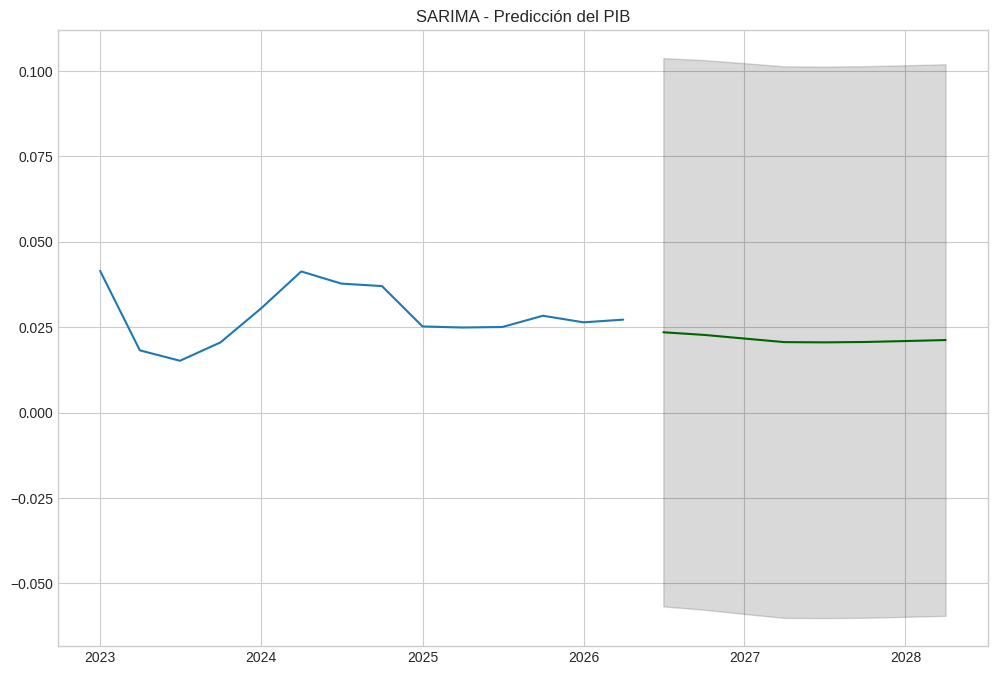

In [103]:
# Y también predecimos hacia el futuro
mod = sm.tsa.statespace.SARIMAX(tvpib,order=(1,0,2),seasonal_order=(1,0,0,4), trend="c",
                                enforce_stationarity=False, enforce_invertibility=False)
pred = results.get_prediction(start="2026-07-01",end="2028-04-01")
pred_ci = pred.conf_int()
# Creando las series para su representación gráfica
fitted_series = pred.predicted_mean
lower_series = pred_ci["lower ive"]
upper_series = pred_ci["upper ive"]
# Gráfico
fig,ax=plt.subplots(figsize=(12,8))
ax.plot(tvpib["2023":])
ax.plot(fitted_series["2023":], color='darkgreen')
ax.fill_between(lower_series["2023":].index,
                 lower_series["2023":],
                 upper_series["2023":],
                 color='k', alpha=.15)
ax.set_title("SARIMA - Predicción del PIB")
plt.show()

In [108]:
# Importamos los datos de afiliaciones y consumo eléctrico
inds=pd.read_excel("/content/Clase_SarimaxDatos.xlsx", sheet_name="BDSICE SS Y GWH")
inds.columns=["periodo","ss","gwh"] # Renombro columnas
inds["periodo"]=inds["periodo"].astype(str)  # Convierto columna de fecha en string
inds["periodo"]=inds["periodo"].str[:4]+"-"+inds["periodo"].str[-2:]  # Transformo columnas de fecha en formato reconocible por pandas
inds["periodo"]=pd.to_datetime(inds["periodo"]) # Convierto en formato datetime
inds.set_index("periodo", inplace=True) # Establezco columna de fecha como index

In [109]:
# Trimestralizar > Tasas de variación > train/test split > comparación

# Trimestralizar
inds = inds.resample("QS").mean()

# Tasas de variación
tvinds = inds.pct_change(4)

# Train/test split
tvinds_train=tvinds.loc["1996-01-01":"2024-04-01"]  # Ahora empezamos en el 96, pues para el 95 no se puede calcular
tvinds_test=tvinds.loc["2024-07-01":"2026-04-01"]
tvinds_pib=tvinds.loc["1996-01-01":"2026-04-01"] # Periodo completo para el que tenemos datos de PIB
tvinds_out=tvinds.loc["2026-07-01":"2026-07-01"] # Timestre extra para el que tenemos las variables exógenas
print(len(train),len(test),len(tvinds_pib), len(tvinds_out))
# Correlaciones
print("Correlación crec PIB - Crec Afiliaciones: ", np.corrcoef(train.ive, tvinds_train['ss'])[0,1])
print("Correlación crec PIB - Crec Consumo eléct: ",np.corrcoef(train.ive, tvinds_train['gwh'])[0,1])


114 8 122 1
Correlación crec PIB - Crec Afiliaciones:  0.7467043439672267
Correlación crec PIB - Crec Consumo eléct:  0.6285535133127238


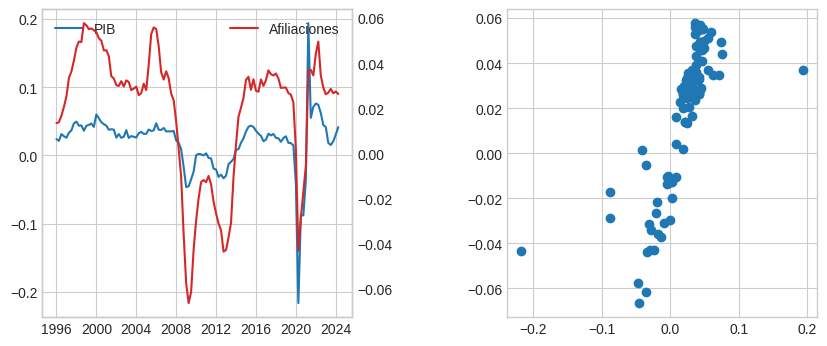

In [114]:
fig,ax=plt.subplots(1,2,figsize=(10,4))
ax[0].plot(train, label="PIB")
ax01 = ax[0].twinx()  # aquí se establece un segundo eje Y que comparte el mismo eje X
ax01.plot(tvinds_train['ss'],color='tab:red', label="Afiliaciones")
ax01.grid(False)
ax[0].legend()
ax01.legend()
ax[1].scatter(train.ive, tvinds_train['ss']) # vemos que hay una correlación alta y por tanto puede usarse como variable exógena
plt.subplots_adjust(wspace=0.5)
plt.show()

In [115]:
# Especificamos y estimamos el modelo
results = sm.tsa.statespace.SARIMAX(train, exog=tvinds_train['ss'],order=(1,0,2),seasonal_order=(1,0,0,4), trend="c",
                                    enforce_stationarity=False, enforce_invertibility=False).fit()
print(results.summary())

                                     SARIMAX Results                                      
Dep. Variable:                                ive   No. Observations:                  114
Model:             SARIMAX(1, 0, 2)x(1, 0, [], 4)   Log Likelihood                 263.704
Date:                            Tue, 24 Nov 2026   AIC                           -513.407
Time:                                    10:19:08   BIC                           -494.568
Sample:                                01-01-1996   HQIC                          -505.767
                                     - 04-01-2024                                         
Covariance Type:                              opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
intercept     -0.0013      0.003     -0.455      0.649      -0.007       0.004
ss             1.6002      0.207   

/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/statespace/mlemodel.py:737: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(


In [116]:
# Capacidad para predecir
pred = results.get_prediction('2024-07-01','2026-04-01', exog=tvinds_test['ss'], dynamic=False)
forecast_accuracy(pred.predicted_mean, test.ive)

{'rmse': np.float64(0.003475097610502251), 'mape': np.float64(0.10484661989539033), 'corr': np.float64(0.8204633526431305)}


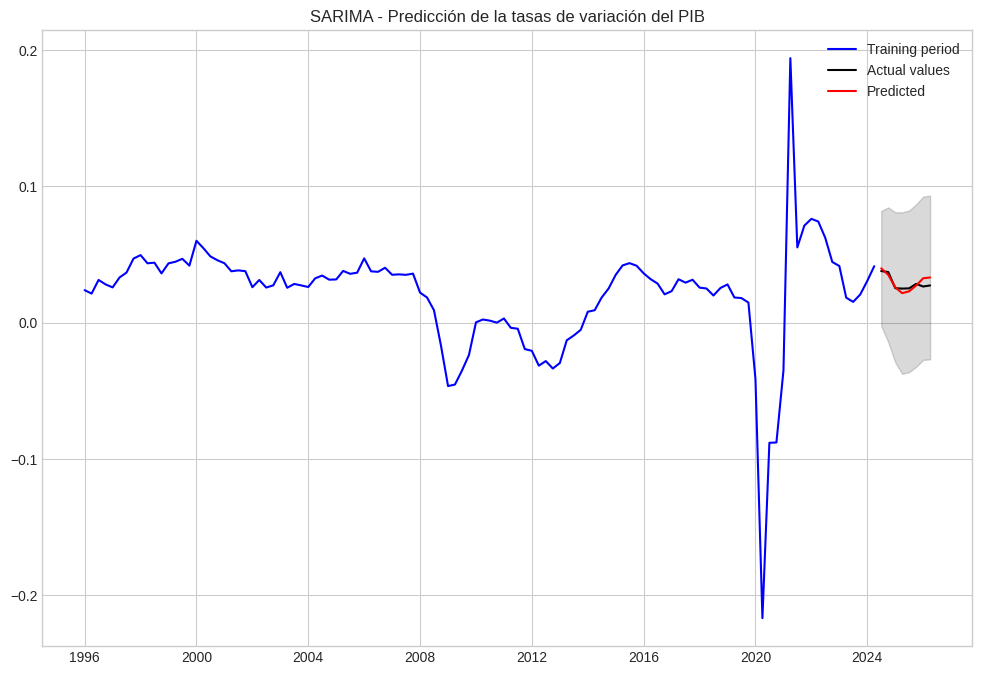

In [117]:
# Dibujamos la predicción:
pred_ci = pred.conf_int()
# Creando las series para su representación gráfica
fitted_series = pred.predicted_mean
lower_series = pred_ci["lower ive"]
upper_series = pred_ci["upper ive"]
# Gráfico -
fig,ax=plt.subplots(figsize=(12,8))
ax.plot(train, label="Training period", color="b") #con [-60:] evito representar la serie completa
ax.plot(test, label="Actual values", color="k")
ax.plot(fitted_series, label="Predicted", color='r')
ax.fill_between(lower_series.index,
                 lower_series,
                 upper_series,
                 color='k', alpha=.15)
ax.legend()
ax.set_title("SARIMA - Predicción de la tasas de variación del PIB")
plt.show()

/tmp/ipykernel_794/4068300086.py:5: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  ax.plot(lower_series.index[-1],lower_series[-1], marker="_", color='darkgreen')
/tmp/ipykernel_794/4068300086.py:6: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  ax.plot(lower_series.index[-1], upper_series[-1], marker="_", color='darkgreen')


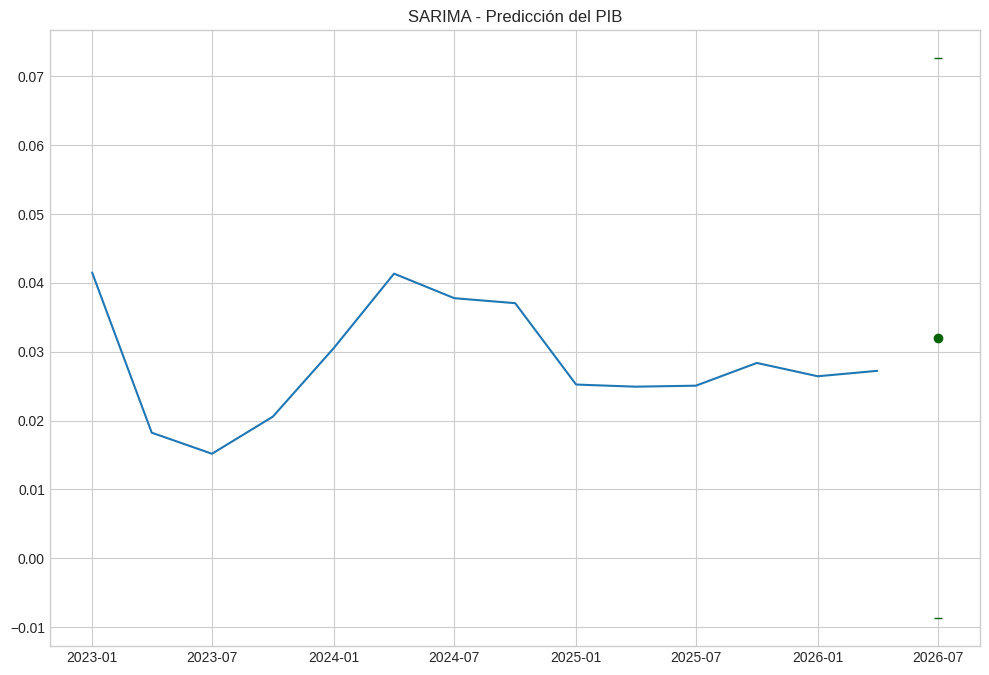

In [138]:
# Y también predecimos hacia el futuro
results = sm.tsa.statespace.SARIMAX(tvpib.loc["1996-01-01":"2026-04-01"], exog=tvinds_pib['ss'], order=(1,0,2),seasonal_order=(1,0,0,4), trend="c",
                                enforce_stationarity=False, enforce_invertibility=False).fit()
pred = results.get_prediction(start="2026-07-01",end="2026-07-01", exog=tvinds_out['ss'], dynamic=False)
pred_ci = pred.conf_int()
# Creando las series para su representación gráfica
fitted_series = pred.predicted_mean
lower_series = pred_ci["lower ive"]
upper_series = pred_ci["upper ive"]
# Gráfico
fig,ax=plt.subplots(figsize=(12,8))
ax.plot(tvpib["2023":])
ax.plot(fitted_series[-1:], marker="o", color='darkgreen')
ax.plot(lower_series.index[-1],lower_series[-1], marker="_", color='darkgreen')
ax.plot(lower_series.index[-1], upper_series[-1], marker="_", color='darkgreen')
ax.set_title("SARIMAX - Predicción del PIB")
plt.show()

## Modelización y predicción de la tasa de paro

El ejercicio consiste en modelizar con el SARIMA y SARIMAX la tasa de paro hasta el segundo trimestre del 2026 y predecir el tercer trimestre usando las afiliaciones como variable exógena.

In [ ]:
# Importar datos y procesarlos
tp=pd.read_excel("/content/65219.xlsx")
tp=tp.iloc[7:106]
tp.columns=["periodo","tasa"]
tp['periodo']=tp.periodo.str[:4]+"Q"+tp.periodo.str[-1:]
tp['periodo']=pd.to_datetime(tp['periodo'])
tp.set_index("periodo",inplace=True)
tp=tp.astype(float)

# Train/test split
train=tp.loc["2002-01-01":"2024-04-01"]
test=tp.loc["2024-07-01":"2026-07-01"] # (el dato del tercer trimestre de 2026 lo dejamos fuera)
print(len(train),len(test))

**HOJA DE RUTA**

-- Con la train dataset --
Analizar serie y su correlograma
Test de raíz unitaria
Decidir si tomar diferencias estacionales y/o primeras diferencias
Mostrar otra vez los gráficos de correlogramas, con la serie transformada.
Decidir los parámetros del modelo
Estimar el modelo y ver el resumen del mismo

-- Out of sample validation --
Predecir con el modelo para el periodo de la test dataset
Calcular métricas de bondad de la predicción comparando la predicción con la test dataset
Visualizar la predicción

-- Predecir hacia el futuro ---